# Step 03 — Labelbox Export → Trainable Dataset

Fuses the Labelbox NDJSON export with the local page images into a dataset
you can actually use: cropped regions per class, COCO-format annotations,
and YOLO-format labels.

**Paths below match the current folder layout:**
```
2026/
  My_code/
    step03_labelbox_export/   <- this notebook lives here
  Pre-Pages-2Annotate/      <- ndjson export, manifest.csv, topic image folders
  Outputs/                  <- results are written here
```

Labelbox never exports rendered/annotated images — only per-object bounding
box coordinates referencing the *original* uploaded image (true of every
annotation tool: COCO, CVAT, Label Studio all work the same way). This
notebook is the bridge: it matches each exported box to your local PNG via
`data_row.external_id` (the filename the image had when uploaded), crops the
region out, and writes it alongside full-page COCO/YOLO annotations.

**Figure is split by subtype.** A box labeled `Figure` in Labelbox carries a
nested Diagram/Plot classification. Rather than dumping every Figure crop
into one folder, this notebook splits them: `Plot/`, `Diagram/`,
`Figure_Mixed/` (carries both tags), and `Figure_Unlabeled/` (neither tag
set). Plot crops are what feed the plot-digitization stage next, so keeping
them separate from generic diagrams matters — set `SPLIT_FIGURE_SUBTYPE =
False` below to turn this off and get the old single `Figure/` folder back.

**Composite ("mixed") figures produce two separate outputs.** Some figures
mix e.g. SEM micrographs with a real data plot in one panel — those get
tagged with both Diagram and Plot, landing in `Figure_Mixed`. The outer
`Figure_Mixed` box is the whole figure region as drawn (panels *and*
caption together) — exactly what a page-layout detector (Dolphin/Docling)
needs to learn to locate, so it's kept as its own category in the
**detector dataset** (`coco_annotations.json` / `yolo/` / `crops/<class>`),
never dropped or relabeled.

Once you've gone back and added tighter Plot/Diagram sub-boxes for the
individual panels (nested inside the original box), those sub-boxes would
overlap the outer box with a different class if left in the same detector
dataset — two ground-truth boxes for the same pixels, which is exactly the
kind of label noise object detectors are bad at learning from. So this
notebook excludes them from the detector dataset (any Plot/Diagram box that
sits almost entirely inside a `Figure_Mixed` box — ≥ `CONTAINMENT_THRESHOLD`
of its own area — is marked **nested_child_of_mixed**), but does NOT throw
them away: instead they feed a second output, **extraction crops**
(`extraction_crops/<class>`, classes set by `EXTRACTION_CLASSES` — default
just `Plot`), pulled from every matching box regardless of nesting. That's
where the tight, caption-free crop is exactly what's wanted for a
downstream model like DePlot, and the outer box (with its caption and
extra panels) would be the wrong input. A `Figure_Mixed` box with no
resolving children yet is flagged in the report below — it still needs
sub-boxes added.


In [1]:
import json
import csv
from collections import defaultdict
from pathlib import Path

from PIL import Image
import matplotlib.pyplot as plt

# ── paths (adjust here if you move things again) ──
NDJSON_PATH  = Path("..") / ".." / "Pre-Pages-2Annotate" / "Export  project - STEPS-Paper-Annotation - 9_12_2026.ndjson"
IMAGES_ROOT  = Path("..") / ".." / "Pre-Pages-2Annotate"          # searched recursively across all topic folders
OUTPUT_ROOT  = Path("..") / ".." / "Outputs" / "dataset"

LABEL_SELECT = "first"   # "first" = one label per row (default); "all" = every consensus annotator's labels
PAD_CROP     = 0         # pixels of padding to add around each crop
SPLIT_FIGURE_SUBTYPE = True   # split "Figure" into Plot / Diagram / Figure_Mixed / Figure_Unlabeled
CONTAINMENT_THRESHOLD = 0.85  # min fraction of a Plot/Diagram box's area that must lie inside a
                              # Figure_Mixed box for it to count as a resolving sub-box
EXTRACTION_CLASSES = ("Plot",)   # classes also cropped into extraction_crops/<class>/,
                                  # pulled from every matching box regardless of nesting

assert NDJSON_PATH.exists(), f"Export not found at {NDJSON_PATH.resolve()}"
assert IMAGES_ROOT.exists(), f"Images root not found at {IMAGES_ROOT.resolve()}"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"NDJSON:  {NDJSON_PATH.resolve()}")
print(f"Images:  {IMAGES_ROOT.resolve()}")
print(f"Output:  {OUTPUT_ROOT.resolve()}")


NDJSON:  /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/Pre-Pages-2Annotate/Export  project - STEPS-Paper-Annotation - 9_12_2026.ndjson
Images:  /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/Pre-Pages-2Annotate
Output:  /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/Outputs/dataset


## Helper functions

Same logic as `step03_labelbox_export_to_dataset.py` — flattening nested classifications, indexing local images by filename, and picking which label to use when a page has more than one (consensus workflows).

In [2]:
def flatten_classifications(classifications):
    """Turn Labelbox's nested classification structure into ['Name:answer', ...]."""
    out = []
    for c in classifications or []:
        cname = c.get("name", "")
        for ans in c.get("checklist_answers", []):
            out.append(f"{cname}:{ans.get('value', '')}")
            out.extend(flatten_classifications(ans.get("classifications", [])))
        if isinstance(c.get("answer"), dict):
            ans = c["answer"]
            out.append(f"{cname}:{ans.get('value', '')}")
            out.extend(flatten_classifications(ans.get("classifications", [])))
    return out


def build_image_index(images_root):
    """Map filename -> full path for every image under images_root (recursive)."""
    index = {}
    for ext in ("*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG"):
        for p in images_root.rglob(ext):
            index[p.name] = p
    return index


def select_labels(labels, mode):
    """
    Labelbox consensus projects can attach multiple independent labels to one
    data row. 'first' -> labels[0] only (default). 'all' -> every label
    (inter-annotator QA — will emit overlapping boxes per annotator by design).
    """
    if not labels:
        return []
    return labels if mode == "all" else [labels[0]]


def effective_class(class_name, subtypes, split_figure_subtype):
    """
    Resolve the class actually used for crop folders / COCO / YOLO categories.
    A 'Figure' box can carry a Diagram/Plot subtype answer (or both, or
    neither); everything else passes through unchanged.
    """
    if not split_figure_subtype or class_name != "Figure":
        return class_name

    tags = {t.split(":", 1)[-1].strip().lower() for t in subtypes if t}
    has_plot = "plot" in tags
    has_diagram = "diagram" in tags

    if has_plot and has_diagram:
        return "Figure_Mixed"
    if has_plot:
        return "Plot"
    if has_diagram:
        return "Diagram"
    return "Figure_Unlabeled"


def containment_ratio(inner, outer):
    """
    Fraction of `inner`'s box area that lies inside `outer`'s box.
    Both are Labelbox bounding_box dicts: {top, left, width, height}.
    1.0 = inner is fully inside outer; 0.0 = no overlap at all.
    """
    ix1, iy1 = inner["left"], inner["top"]
    ix2, iy2 = ix1 + inner["width"], iy1 + inner["height"]
    ox1, oy1 = outer["left"], outer["top"]
    ox2, oy2 = ox1 + outer["width"], oy1 + outer["height"]

    cx1, cy1 = max(ix1, ox1), max(iy1, oy1)
    cx2, cy2 = min(ix2, ox2), min(iy2, oy2)
    inter_area = max(0.0, cx2 - cx1) * max(0.0, cy2 - cy1)
    inner_area = max(1e-9, inner["width"] * inner["height"])
    return inter_area / inner_area


def resolve_composites(page_objects, containment_threshold=CONTAINMENT_THRESHOLD):
    """
    Mutates `page_objects` in place, adding "nested_child_of_mixed",
    "nested_parent_feature_id", and "mixed_resolved" to each.

    The outer 'Figure_Mixed' box is the whole figure region (panels +
    caption) -- kept as-is for the detector dataset, never dropped. Any
    Plot/Diagram box that sits almost entirely inside it (tighter sub-box
    resolving one of the composite's panels) is marked
    nested_child_of_mixed=True -- excluded from the detector dataset (would
    overlap the outer box with a different class) but still cropped
    separately into extraction_crops/ for classes in EXTRACTION_CLASSES.
    A 'Figure_Mixed' box with no such children has mixed_resolved=False --
    it still needs sub-boxes added.
    """
    for obj in page_objects:
        obj["nested_child_of_mixed"] = False
        obj["nested_parent_feature_id"] = ""
        obj["mixed_resolved"] = False

    composites = [o for o in page_objects if o["class_name"] == "Figure_Mixed"]
    for comp in composites:
        children = [
            o for o in page_objects
            if o is not comp
            and o["class_name"] in ("Plot", "Diagram")
            and containment_ratio(o["bbox"], comp["bbox"]) >= containment_threshold
        ]
        if children:
            comp["mixed_resolved"] = True
        for child in children:
            child["nested_child_of_mixed"] = True
            child["nested_parent_feature_id"] = comp["obj"].get("feature_id", "")


image_index = build_image_index(IMAGES_ROOT)
print(f"Indexed {len(image_index)} local image(s) under {IMAGES_ROOT}/")


Indexed 1150 local image(s) under ../../Pre-Pages-2Annotate/


## Walk the export and build the dataset

For every annotated box: record it in a flat CSV, register it in COCO format, write a YOLO `.txt` line, and crop the region out of the local page image into `crops/<class>/`.

In [3]:
crops_dir = OUTPUT_ROOT / "crops"
yolo_dir  = OUTPUT_ROOT / "yolo"
extraction_dir = OUTPUT_ROOT / "extraction_crops"
crops_dir.mkdir(parents=True, exist_ok=True)
yolo_dir.mkdir(parents=True, exist_ok=True)
extraction_dir.mkdir(parents=True, exist_ok=True)

csv_rows = []
coco_images, coco_annotations = [], []
categories = {}
class_counts = defaultdict(int)
extraction_counts = defaultdict(int)
missing_images = set()
no_graphics_rows = 0
nested_excluded_count = 0   # nested sub-boxes excluded from the detector dataset
unresolved_mixed = []       # external_ids with a Figure_Mixed box still needing sub-boxes
ann_id = 0
img_id = 0

with open(NDJSON_PATH, "r") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        row = json.loads(line)

        external_id = row.get("data_row", {}).get("external_id", "")
        media = row.get("media_attributes", {})
        declared_w, declared_h = media.get("width"), media.get("height")

        local_path = image_index.get(external_id)
        if local_path is None:
            missing_images.add(external_id)

        if local_path is not None:
            with Image.open(local_path) as im:
                img_w, img_h = im.size
        elif declared_w and declared_h:
            img_w, img_h = declared_w, declared_h
        else:
            img_w, img_h = None, None

        coco_img_id = None

        for project_id, project in row.get("projects", {}).items():
            labels = select_labels(project.get("labels", []), LABEL_SELECT)

            for label in labels:
                objects = label.get("annotations", {}).get("objects", [])
                top_classifications = label.get("annotations", {}).get("classifications", [])

                if not objects and any(
                    "no_graphics" in str(c).lower() for c in top_classifications
                ):
                    no_graphics_rows += 1

                # ── pass 1: build the page's object list with resolved classes ──
                page_objects = []
                for obj in objects:
                    bbox = obj.get("bounding_box")
                    if not bbox:
                        continue  # classification-only annotation, no box to crop

                    raw_class = obj.get("name", "unlabeled")
                    subtypes = flatten_classifications(obj.get("classifications", []))
                    class_name = effective_class(raw_class, subtypes, SPLIT_FIGURE_SUBTYPE)

                    page_objects.append({
                        "obj": obj, "bbox": bbox, "raw_class": raw_class,
                        "subtypes": subtypes, "class_name": class_name,
                    })

                # ── pass 2: resolve composites (mark nested Plot/Diagram sub-boxes) ──
                resolve_composites(page_objects, CONTAINMENT_THRESHOLD)
                if any(o["class_name"] == "Figure_Mixed" and not o["mixed_resolved"]
                       for o in page_objects):
                    unresolved_mixed.append(external_id)

                # ── pass 3: emit CSV / detector dataset (COCO/YOLO/crops) / extraction crops ──
                for po in page_objects:
                    obj, bbox = po["obj"], po["bbox"]
                    class_name, raw_class, subtypes = po["class_name"], po["raw_class"], po["subtypes"]
                    nested = po["nested_child_of_mixed"]

                    top, left = bbox["top"], bbox["left"]
                    width, height = bbox["width"], bbox["height"]

                    if nested:
                        nested_excluded_count += 1
                    else:
                        class_counts[class_name] += 1

                    csv_rows.append({
                        "image": external_id, "class": class_name, "raw_class": raw_class,
                        "subtypes": ";".join(subtypes),
                        "nested_child_of_mixed": nested,
                        "nested_parent_feature_id": po["nested_parent_feature_id"],
                        "top": top, "left": left, "width": width, "height": height,
                        "img_width": img_w, "img_height": img_h,
                        "feature_id": obj.get("feature_id", ""),
                        "project": project.get("name", project_id),
                    })

                    # ── extraction crops: every matching class, nested or not ──
                    if class_name in EXTRACTION_CLASSES and local_path is not None:
                        extraction_counts[class_name] += 1
                        l = max(0, int(left) - PAD_CROP)
                        t = max(0, int(top) - PAD_CROP)
                        r = min(img_w, int(left + width) + PAD_CROP)
                        b = min(img_h, int(top + height) + PAD_CROP)
                        with Image.open(local_path) as im:
                            crop = im.crop((l, t, r, b))
                            ex_dir = extraction_dir / class_name
                            ex_dir.mkdir(exist_ok=True)
                            out_name = f"{Path(external_id).stem}__{obj.get('feature_id', ann_id)}.png"
                            crop.save(ex_dir / out_name)

                    if nested:
                        continue  # excluded from the detector dataset -- see markdown above

                    if coco_img_id is None and img_w and img_h:
                        coco_img_id = img_id
                        coco_images.append({"id": coco_img_id, "file_name": external_id,
                                             "width": img_w, "height": img_h})
                        img_id += 1

                    if class_name not in categories:
                        categories[class_name] = len(categories)

                    if coco_img_id is not None:
                        ann_id += 1
                        coco_annotations.append({
                            "id": ann_id, "image_id": coco_img_id,
                            "category_id": categories[class_name],
                            "bbox": [left, top, width, height],
                            "area": width * height, "iscrowd": 0,
                        })
                        cx, cy = (left + width / 2) / img_w, (top + height / 2) / img_h
                        nw, nh = width / img_w, height / img_h
                        yolo_txt = yolo_dir / (Path(external_id).stem + ".txt")
                        with open(yolo_txt, "a") as yf:
                            yf.write(f"{categories[class_name]} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}\n")

                    if local_path is not None:
                        l = max(0, int(left) - PAD_CROP)
                        t = max(0, int(top) - PAD_CROP)
                        r = min(img_w, int(left + width) + PAD_CROP)
                        b = min(img_h, int(top + height) + PAD_CROP)
                        with Image.open(local_path) as im:
                            crop = im.crop((l, t, r, b))
                            class_dir = crops_dir / class_name
                            class_dir.mkdir(exist_ok=True)
                            out_name = f"{Path(external_id).stem}__{obj.get('feature_id', ann_id)}.png"
                            crop.save(class_dir / out_name)

print("DETECTOR DATASET  (coco_annotations.json / yolo / crops/<class>)")
print(f"Objects: {sum(class_counts.values())}")
for name, count in sorted(class_counts.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<20} {count}")
print(f"\nPages with 'No Graphics': {no_graphics_rows}")
print(f"Images referenced:        {img_id}")
print(f"Local images not found:   {len(missing_images)}")

print(f"\nNested Plot/Diagram sub-boxes excluded from the detector dataset "
      f"(kept only in the CSV + extraction crops): {nested_excluded_count}")
if unresolved_mixed:
    print(f"Still-ambiguous 'Figure_Mixed' boxes needing sub-boxes "
          f"({len(unresolved_mixed)} page(s)):")
    for eid in unresolved_mixed:
        print(f"    - {eid}")
else:
    print("Still-ambiguous 'Figure_Mixed' boxes needing sub-boxes: none")

print(f"\nEXTRACTION CROPS  (extraction_crops/<class>) -- classes: {', '.join(EXTRACTION_CLASSES)}")
if extraction_counts:
    for name, count in sorted(extraction_counts.items(), key=lambda kv: -kv[1]):
        print(f"  {name:<20} {count}")
else:
    print("  (none -- no boxes matched EXTRACTION_CLASSES)")


DETECTOR DATASET  (coco_annotations.json / yolo / crops/<class>)
Objects: 105
  Table                43
  Plot                 39
  Diagram              18
  Figure_Mixed         5

Pages with 'No Graphics': 35
Images referenced:        78
Local images not found:   0

Nested Plot/Diagram sub-boxes excluded from the detector dataset (kept only in the CSV + extraction crops): 11
Still-ambiguous 'Figure_Mixed' boxes needing sub-boxes: none

EXTRACTION CROPS  (extraction_crops/<class>) -- classes: Plot
  Plot                 44


## Write outputs

In [4]:
csv_path = OUTPUT_ROOT / "annotations_flat.csv"
fieldnames = list(csv_rows[0].keys()) if csv_rows else [
    "image", "class", "raw_class", "subtypes", "nested_child_of_mixed",
    "nested_parent_feature_id", "top", "left", "width", "height",
    "img_width", "img_height", "feature_id", "project",
]
with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(csv_rows)

coco = {
    "images": coco_images,
    "annotations": coco_annotations,
    "categories": [{"id": i, "name": n} for n, i in categories.items()],
}
with open(OUTPUT_ROOT / "coco_annotations.json", "w") as f:
    json.dump(coco, f, indent=2)

with open(yolo_dir / "classes.txt", "w") as f:
    for name, _ in sorted(categories.items(), key=lambda kv: kv[1]):
        f.write(name + "\n")

print(f"Written to {OUTPUT_ROOT}/")
print("  annotations_flat.csv               one row per annotated object")
print("  coco_annotations.json              detector dataset, full-page COCO format")
print("  yolo/*.txt + classes.txt           detector dataset, YOLO format")
print("  crops/<class>/*.png                detector dataset, cropped regions by class")
print("  extraction_crops/<class>/*.png     tight crops for plot digitization, "
      "incl. resolved composites' inner boxes")


Written to ../../Outputs/dataset/
  annotations_flat.csv               one row per annotated object
  coco_annotations.json              detector dataset, full-page COCO format
  yolo/*.txt + classes.txt           detector dataset, YOLO format
  crops/<class>/*.png                detector dataset, cropped regions by class
  extraction_crops/<class>/*.png     tight crops for plot digitization, incl. resolved composites' inner boxes


## Preview a few crops

A quick visual sanity check — confirms the bounding boxes actually landed on the right pixels before you trust the rest of the dataset.

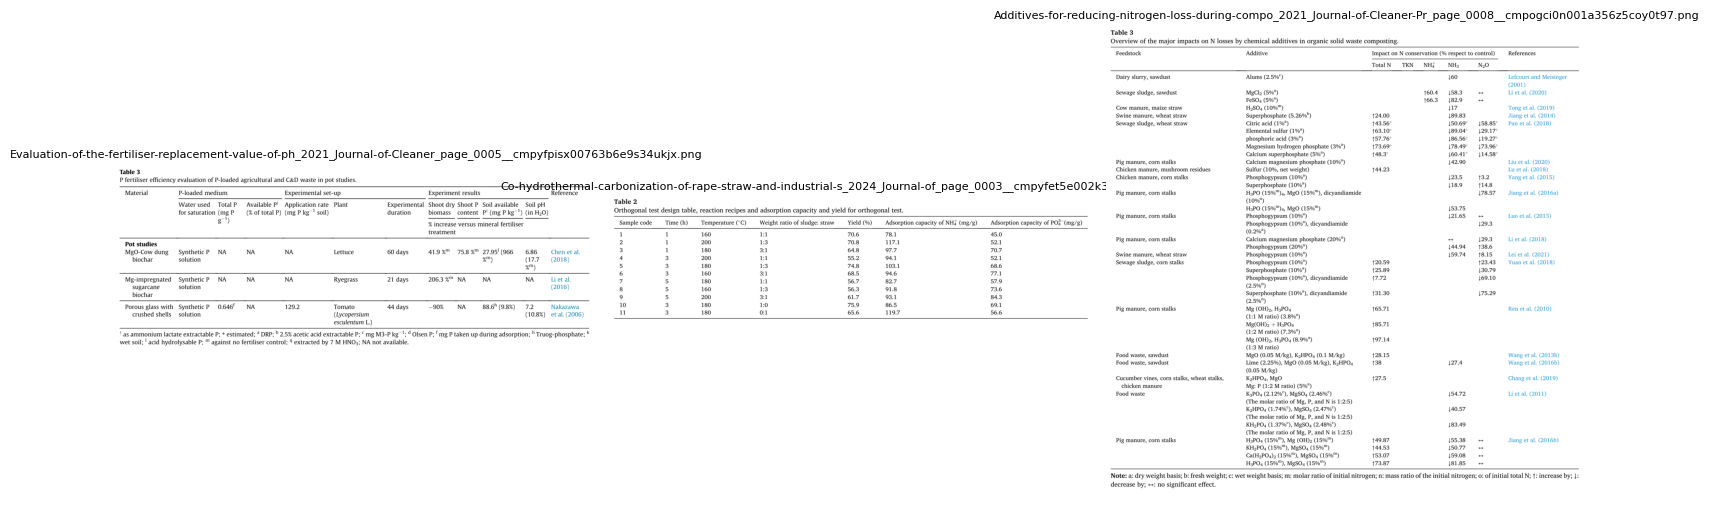

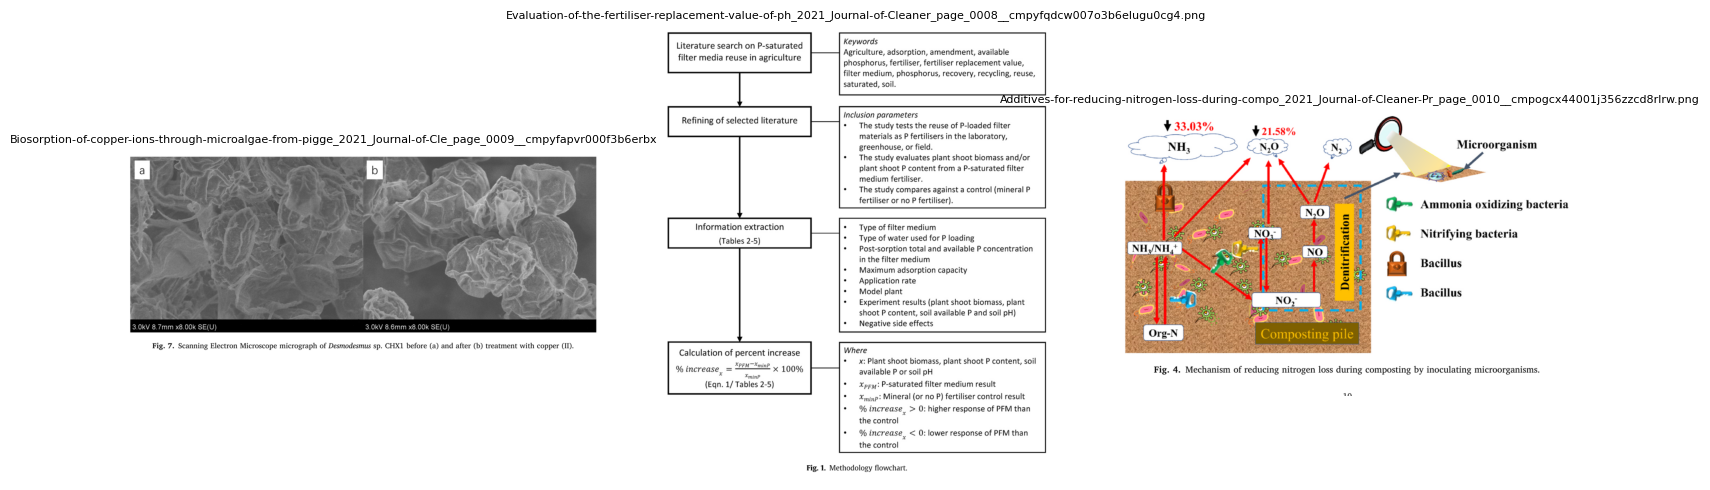

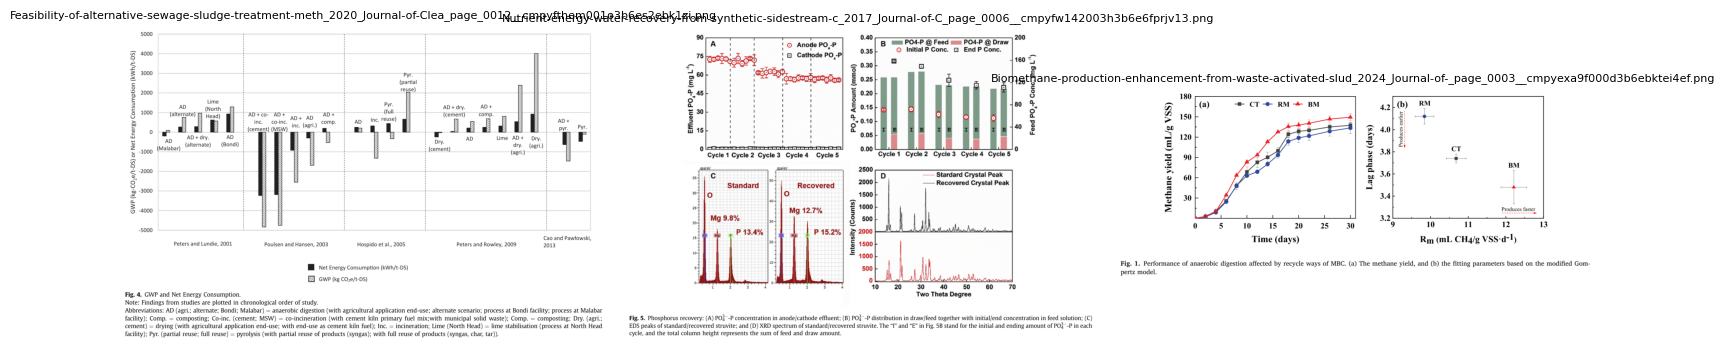

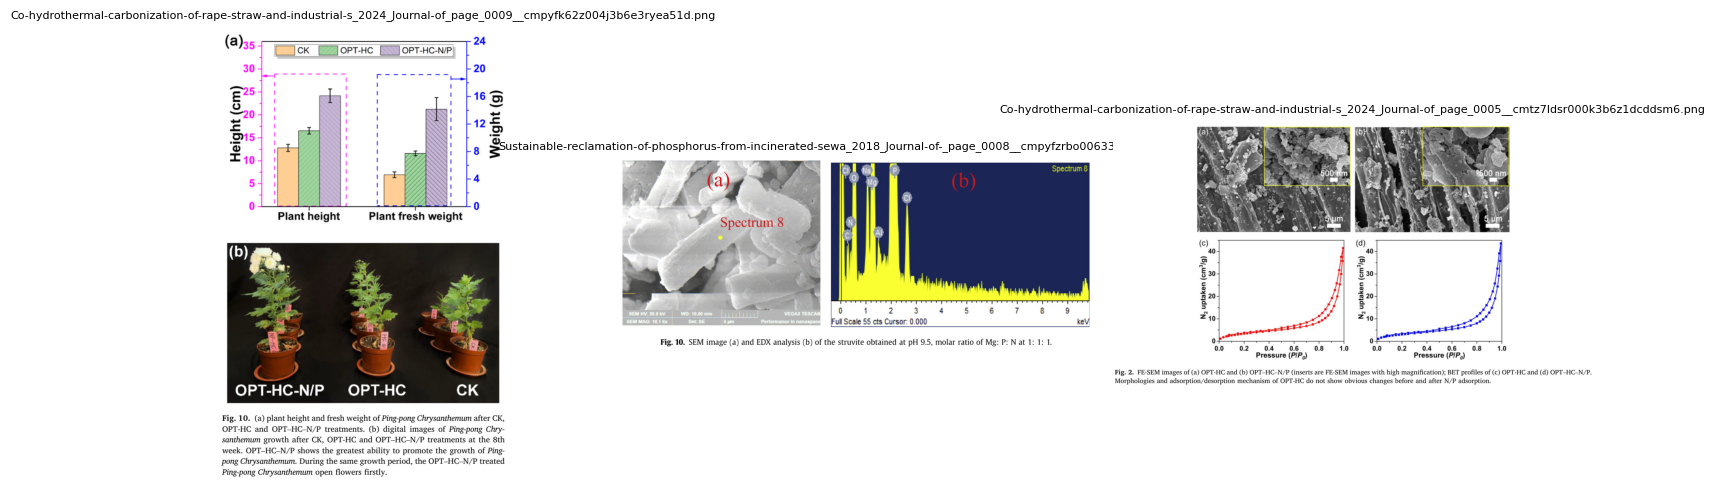

In [5]:
import random

def preview_class(class_name, n=3):
    class_dir = crops_dir / class_name
    if not class_dir.exists():
        print(f"No crops for class '{class_name}'")
        return
    files = sorted(class_dir.glob("*.png"))
    if not files:
        print(f"No crop files found in {class_dir}")
        return
    sample = random.sample(files, min(n, len(files)))

    fig, axes = plt.subplots(1, len(sample), figsize=(5 * len(sample), 5))
    if len(sample) == 1:
        axes = [axes]
    for ax, path in zip(axes, sample):
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

for cls in categories:
    preview_class(cls, n=3)


## Preview extraction crops

The tight, caption-free crops meant for plot digitization -- pulled from every matching box regardless of nesting, so this includes both standalone Plot boxes and the resolved composites' inner Plot sub-boxes.

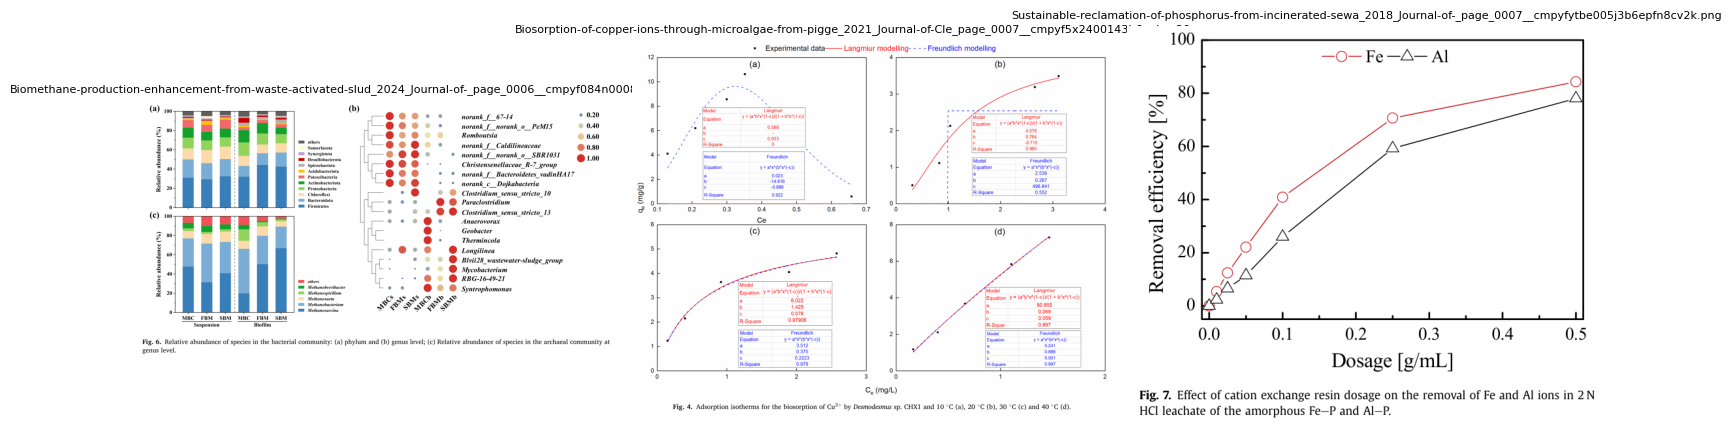

In [6]:
def preview_extraction_class(class_name, n=3):
    class_dir = extraction_dir / class_name
    if not class_dir.exists():
        print(f"No extraction crops for class '{class_name}'")
        return
    files = sorted(class_dir.glob("*.png"))
    if not files:
        print(f"No crop files found in {class_dir}")
        return
    sample = random.sample(files, min(n, len(files)))

    fig, axes = plt.subplots(1, len(sample), figsize=(5 * len(sample), 5))
    if len(sample) == 1:
        axes = [axes]
    for ax, path in zip(axes, sample):
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(path.name, fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

for cls in EXTRACTION_CLASSES:
    preview_extraction_class(cls, n=3)


## Class distribution

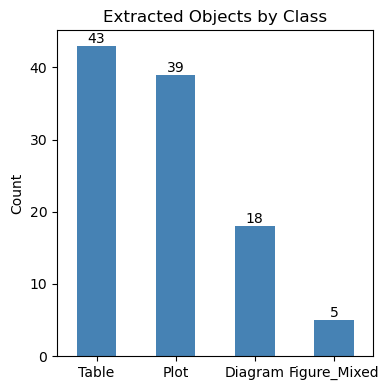

In [7]:
import pandas as pd

pd.Series(class_counts).sort_values(ascending=False).plot(
    kind="bar", figsize=(4, 4), color="steelblue"
).bar_label(plt.gca().containers[0])
plt.ylabel("Count")
plt.title("Extracted Objects by Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
